In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("heart.csv")
print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR ExerciseAngina  Oldpeak ST_Slope  \
0   40   M           ATA        140          289          0     Normal    172              N      0.0       Up   
1   49   F           NAP        160          180          0     Normal    156              N      1.0     Flat   
2   37   M           ATA        130          283          0         ST     98              N      0.0       Up   
3   48   F           ASY        138          214          0     Normal    108              Y      1.5     Flat   
4   54   M           NAP        150          195          0     Normal    122              N      0.0       Up   

   HeartDisease  
0             0  
1             1  
2             0  
3             1  
4             0  


In [4]:
print("First 5 rows:")
print(df.head())
print("\nLast 5 rows:")
print(df.tail())
print("\nA random sample of 5 rows:")
print(df.sample(5, random_state=42))

First 5 rows:
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR ExerciseAngina  Oldpeak ST_Slope  \
0   40   M           ATA        140          289          0     Normal    172              N      0.0       Up   
1   49   F           NAP        160          180          0     Normal    156              N      1.0     Flat   
2   37   M           ATA        130          283          0         ST     98              N      0.0       Up   
3   48   F           ASY        138          214          0     Normal    108              Y      1.5     Flat   
4   54   M           NAP        150          195          0     Normal    122              N      0.0       Up   

   HeartDisease  
0             0  
1             1  
2             0  
3             1  
4             0  

Last 5 rows:
     Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR ExerciseAngina  Oldpeak ST_Slope  \
913   45   M            TA        110          264          0  

In [5]:
print("Shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

Shape: (918, 12)
Number of rows: 918
Number of columns: 12

Column names:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']


In [6]:
df.info()
numeric_columns = df.select_dtypes(include="number").columns.tolist()
text_columns = df.select_dtypes(exclude="number").columns.tolist()
print("\nNumeric columns:", numeric_columns)
print("Text columns:", text_columns)

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB

Numeric columns: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease']
Text columns: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


In [7]:
print(df.describe().round(2))
print("\nText columns:")
print(df.describe(exclude="number"))

          Age  RestingBP  Cholesterol  FastingBS   MaxHR  Oldpeak  HeartDisease
count  918.00     918.00       918.00     918.00  918.00   918.00        918.00
mean    53.51     132.40       198.80       0.23  136.81     0.89          0.55
std      9.43      18.51       109.38       0.42   25.46     1.07          0.50
min     28.00       0.00         0.00       0.00   60.00    -2.60          0.00
25%     47.00     120.00       173.25       0.00  120.00     0.00          0.00
50%     54.00     130.00       223.00       0.00  138.00     0.60          1.00
75%     60.00     140.00       267.00       0.00  156.00     1.50          1.00
max     77.00     200.00       603.00       1.00  202.00     6.20          1.00

Text columns:
        Sex ChestPainType RestingECG ExerciseAngina ST_Slope
count   918           918        918            918      918
unique    2             4          3              2        3
top       M           ASY     Normal              N     Flat
freq    725          

HeartDisease
0    410
1    508
Name: count, dtype: int64

Percentage:
HeartDisease
0    44.7
1    55.3
Name: proportion, dtype: float64


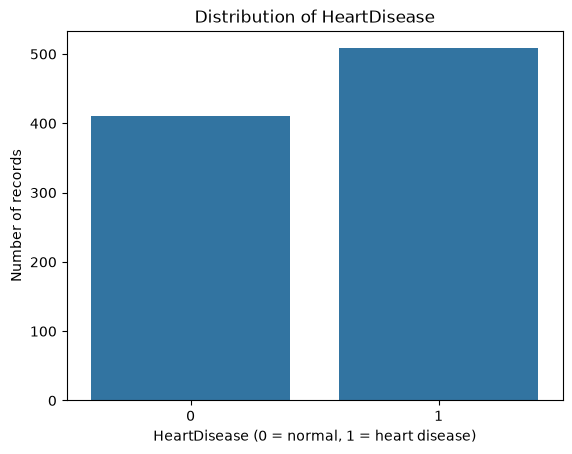

In [8]:
print(df["HeartDisease"].value_counts().sort_index())
print("\nPercentage:")
print((df["HeartDisease"].value_counts(normalize=True).sort_index() * 
100).round(1))
sns.countplot(data=df, x="HeartDisease")
plt.title("Distribution of HeartDisease")
plt.xlabel("HeartDisease (0 = normal, 1 = heart disease)")
plt.ylabel("Number of records")
plt.show()


Sex:
Sex
M    725
F    193
Name: count, dtype: int64

ChestPainType:
ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64

RestingECG:
RestingECG
Normal    552
LVH       188
ST        178
Name: count, dtype: int64

ExerciseAngina:
ExerciseAngina
N    547
Y    371
Name: count, dtype: int64

ST_Slope:
ST_Slope
Flat    460
Up      395
Down     63
Name: count, dtype: int64


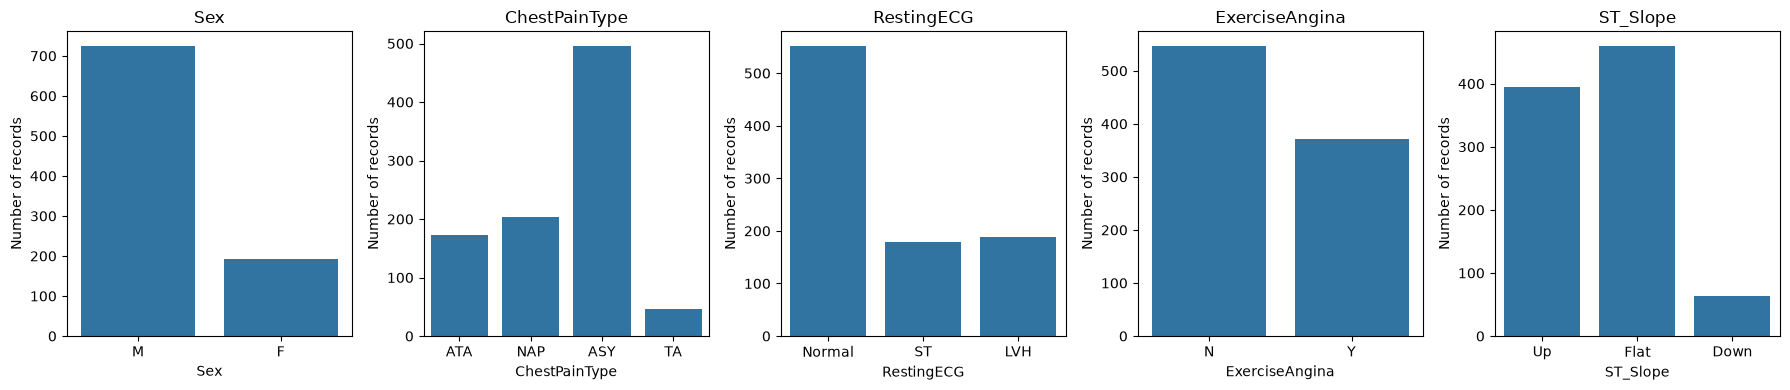

In [9]:
categorical_columns = ["Sex", "ChestPainType", "RestingECG", 
"ExerciseAngina", "ST_Slope"]
for col in categorical_columns:
  print(f"\n{col}:")
  print(df[col].value_counts())
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, categorical_columns):
  sns.countplot(data=df, x=col, ax=ax)
  ax.set_title(col)
  ax.set_xlabel(col)
  ax.set_ylabel("Number of records")
plt.tight_layout()
plt.show()

In [10]:
missing_count = df.isnull().sum()
missing_percent = (df.isnull().mean() * 100).round(2)
missing_report = pd.DataFrame({
"Missing_Count": missing_count,
"Missing_Percent": missing_percent
})
print(missing_report)

                Missing_Count  Missing_Percent
Age                         0              0.0
Sex                         0              0.0
ChestPainType               0              0.0
RestingBP                   0              0.0
Cholesterol                 0              0.0
FastingBS                   0              0.0
RestingECG                  0              0.0
MaxHR                       0              0.0
ExerciseAngina              0              0.0
Oldpeak                     0              0.0
ST_Slope                    0              0.0
HeartDisease                0              0.0


In [11]:
numeric_features_all = ["Age", "RestingBP", "Cholesterol", "FastingBS", 
"MaxHR", "Oldpeak"]
print(df[numeric_features_all].eq(0).sum())
print("\nRecord with RestingBP = 0:")
print(df[df["RestingBP"] == 0])

Age              0
RestingBP        1
Cholesterol    172
FastingBS      704
MaxHR            0
Oldpeak        368
dtype: int64

Record with RestingBP = 0:
     Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR ExerciseAngina  Oldpeak ST_Slope  \
449   55   M           NAP          0            0          0     Normal    155              N      1.5     Flat   

     HeartDisease  
449             1  


In [12]:
print((df[numeric_features_all] < 0).sum())
print("\nNegative Oldpeak values:")
print(df.loc[df["Oldpeak"] < 0, "Oldpeak"].sort_values().tolist())

Age             0
RestingBP       0
Cholesterol     0
FastingBS       0
MaxHR           0
Oldpeak        13
dtype: int64

Negative Oldpeak values:
[-2.6, -2.0, -1.5, -1.1, -1.0, -1.0, -0.9, -0.8, -0.7, -0.5, -0.5, -0.1, -0.1]


In [13]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [14]:
quality_report = pd.DataFrame({
"Data_Type": df.dtypes.astype(str),
"Missing_Values": df.isnull().sum(),
"Zero_Values": (df == 0).sum(),
"Negative_Values": 
df.select_dtypes(include="number").lt(0).sum().reindex(df.columns, 
fill_value=0),
"Unique_Values": df.nunique()
})
print(quality_report)

               Data_Type  Missing_Values  Zero_Values  Negative_Values  Unique_Values
Age                int64               0            0                0             50
Sex                  str               0            0                0              2
ChestPainType        str               0            0                0              4
RestingBP          int64               0            1                0             67
Cholesterol        int64               0          172                0            222
FastingBS          int64               0          704                0              2
RestingECG           str               0            0                0              3
MaxHR              int64               0            0                0            119
ExerciseAngina       str               0            0                0              2
Oldpeak          float64               0          368               13             53
ST_Slope             str               0            0 

In [15]:
df_clean = df.copy()
measurement_columns = ["RestingBP", "Cholesterol"]
df_clean[measurement_columns] = (
df_clean[measurement_columns].replace(0, np.nan)
)
print(df_clean[measurement_columns].isnull().sum())

RestingBP        1
Cholesterol    172
dtype: int64


In [16]:
for col in measurement_columns:
  median_value = df_clean[col].median()
  df_clean[col] = df_clean[col].fillna(median_value)
  print(col, "median =", round(median_value, 2))
print("\nMissing values after filling:")
print(df_clean[measurement_columns].isnull().sum())

RestingBP median = 130.0
Cholesterol median = 237.0

Missing values after filling:
RestingBP      0
Cholesterol    0
dtype: int64


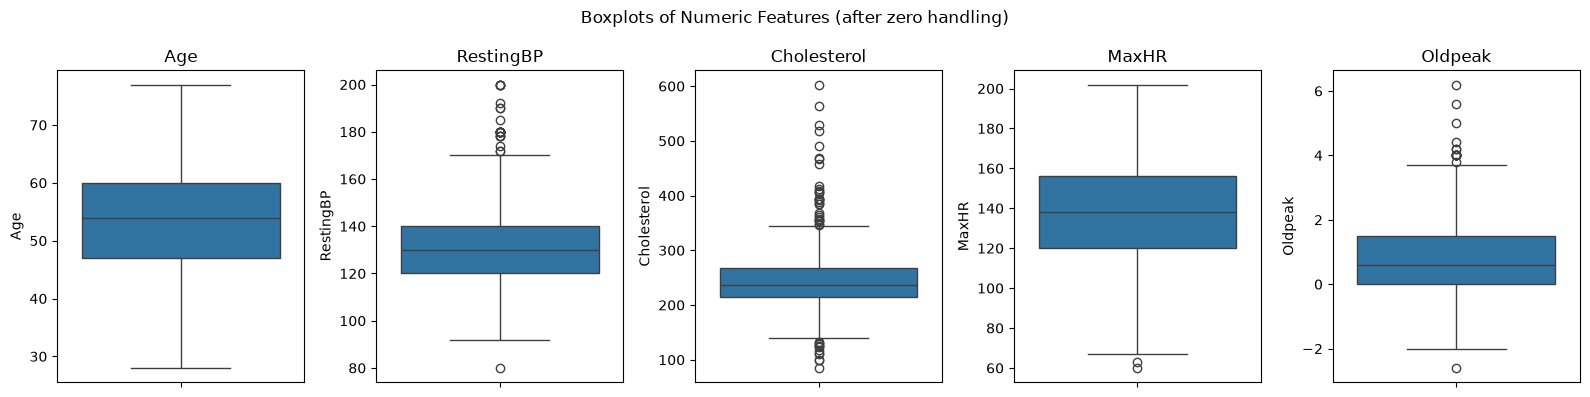

Age: lower = 27.50, upper = 79.50, potentialoutliers = 0
RestingBP: lower = 90.00, upper = 170.00, potentialoutliers = 27
Cholesterol: lower = 134.50, upper = 346.50, potentialoutliers = 41
MaxHR: lower = 66.00, upper = 210.00, potentialoutliers = 2
Oldpeak: lower = -2.25, upper = 3.75, potentialoutliers = 16


In [17]:
outlier_columns = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, col in zip(axes, outlier_columns):
  sns.boxplot(y=df_clean[col], ax=ax)
  ax.set_title(col)
plt.suptitle("Boxplots of Numeric Features (after zero handling)")
plt.tight_layout()
plt.show()
for col in outlier_columns:
  q1 = df_clean[col].quantile(0.25)
  q3 = df_clean[col].quantile(0.75)
  iqr = q3 - q1
  lower = q1 - 1.5 * iqr
  upper = q3 + 1.5 * iqr
  n_outliers = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
  print(f"{col}: lower = {lower:.2f}, upper = {upper:.2f}, potentialoutliers = {n_outliers}")

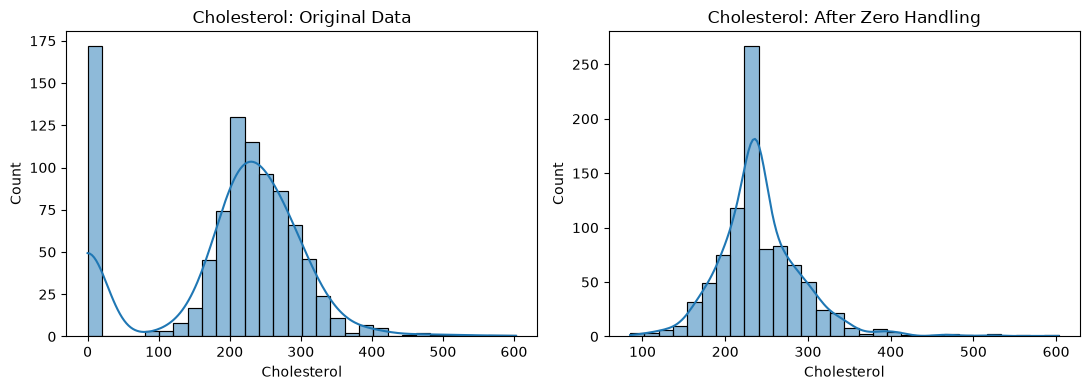

Original  : {'mean': 198.8, 'std': 109.38, 'min': 0.0, '50%': 223.0}
Cleaned   : {'mean': 243.2, 'std': 53.4, 'min': 85.0, '50%': 237.0}


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Cholesterol"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Cholesterol: Original Data")
sns.histplot(df_clean["Cholesterol"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Cholesterol: After Zero Handling")
plt.tight_layout()
plt.show()
print("Original  :", df["Cholesterol"].describe()[["mean", "std", "min", 
"50%"]].round(2).to_dict())
print("Cleaned   :", df_clean["Cholesterol"].describe()[["mean", "std", 
"min", "50%"]].round(2).to_dict())

In [19]:
df_clean.to_csv("heart_cleaned.csv", index=False)
print("Cleaned dataset exported successfully!")
print("New shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())

Cleaned dataset exported successfully!
New shape: (918, 12)
Missing values: 0


In [20]:
X = df.drop(columns="HeartDisease").copy()
y = df["HeartDisease"].copy()
# Convert only the selected zero placeholders to NaN in X
X[measurement_columns] = X[measurement_columns].replace(0, np.nan)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts().sort_index())

X shape: (918, 11)
y shape: (918,)

Target distribution:
HeartDisease
0    410
1    508
Name: count, dtype: int64


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size=0.20,
random_state=42,
stratify=y
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)
print("\nClass percentage in train:")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(1))
print("Class percentage in test:")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(1))

X_train: (734, 11)
X_test : (184, 11)
y_train: (734,)
y_test : (184,)

Class percentage in train:
HeartDisease
0    44.7
1    55.3
Name: proportion, dtype: float64
Class percentage in test:
HeartDisease
0    44.6
1    55.4
Name: proportion, dtype: float64


In [22]:
numeric_features = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
binary_features = ["FastingBS"]
categorical_features = ["Sex", "ChestPainType", "RestingECG", 
"ExerciseAngina", "ST_Slope"]
numeric_pipeline = Pipeline(steps=[
("imputer", SimpleImputer(strategy="median")),
("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer(
transformers=[
("num", numeric_pipeline, numeric_features),
("bin", "passthrough", binary_features),
("cat", categorical_pipeline, categorical_features)
],
verbose_feature_names_out=False
)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape :", X_test_processed.shape)
print("Any NaN in training data:", np.isnan(X_train_processed).sum())

Processed training shape: (734, 20)
Processed testing shape : (184, 20)
Any NaN in training data: 0


In [23]:
processed_train_df = pd.DataFrame(X_train_processed, columns=feature_names)
print(processed_train_df[numeric_features].describe().loc[["mean", 
"std"]].round(2))
print("\nOne-hot columns for ChestPainType (first 5 rows):")
print(processed_train_df.filter(like="ChestPainType").head())
print("\nEach row has exactly one ChestPainType = 1:",
(processed_train_df.filter(like="ChestPainType").sum(axis=1) == 
1).all())

      Age  RestingBP  Cholesterol  MaxHR  Oldpeak
mean  0.0       -0.0          0.0   -0.0      0.0
std   1.0        1.0          1.0    1.0      1.0

One-hot columns for ChestPainType (first 5 rows):
   ChestPainType_ASY  ChestPainType_ATA  ChestPainType_NAP  ChestPainType_TA
0                0.0                1.0                0.0               0.0
1                0.0                1.0                0.0               0.0
2                1.0                0.0                0.0               0.0
3                1.0                0.0                0.0               0.0
4                1.0                0.0                0.0               0.0

Each row has exactly one ChestPainType = 1: True


In [24]:
train_export = processed_train_df.copy()
train_export["HeartDisease"] = y_train.reset_index(drop=True)
test_export = pd.DataFrame(X_test_processed, columns=feature_names)
test_export["HeartDisease"] = y_test.reset_index(drop=True)
train_export.to_csv("heart_train.csv", index=False)
test_export.to_csv("heart_test.csv", index=False)
print("Training and testing files exported.")
print("Train file shape:", train_export.shape)
print("Test file shape :", test_export.shape)

Training and testing files exported.
Train file shape: (734, 21)
Test file shape : (184, 21)
